In [1]:
%pip install seaborn openpyxl

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set clean visual theme
sns.set_theme(style="whitegrid")

# 1. Load the Excel dataset
df = pd.read_excel('ABC Company.xlsx')

# 2. Replace 'Height' column with random integers between 150 and 180
np.random.seed(42)  # Keeps random numbers identical every time you run the notebook
df['Height'] = np.random.randint(150, 181, size=len(df))

# 3. Ensure data consistency and integrity
# Fill missing Salary values with median salary so payroll calculations remain accurate
df['Salary'] = df['Salary'].fillna(df['Salary'].median())
# Fill missing College entries with 'Unknown'
df['College'] = df['College'].fillna('Unknown')
# Remove any duplicate rows
df.drop_duplicates(inplace=True)

# 4. Verify dataset health
print("Dataset Shape:", df.shape)
print("Remaining Missing Values:", df.isnull().sum().sum())
print("\nHeight Column Summary:")
print(df['Height'].describe())


Dataset Shape: (458, 9)
Remaining Missing Values: 0

Height Column Summary:
count    458.000000
mean     165.085153
std        9.412232
min      150.000000
25%      156.250000
50%      165.000000
75%      174.000000
max      180.000000
Name: Height, dtype: float64


--- Employee Distribution by Team ---
                        Employee Count  Percentage (%)
Team                                                  
New Orleans Pelicans                19            4.15
Memphis Grizzlies                   18            3.93
New York Knicks                     16            3.49
Milwaukee Bucks                     16            3.49
Utah Jazz                           16            3.49
Boston Celtics                      15            3.28
Brooklyn Nets                       15            3.28
Philadelphia 76ers                  15            3.28
Toronto Raptors                     15            3.28
Golden State Warriors               15            3.28
Los Angeles Clippers                15            3.28
Los Angeles Lakers                  15            3.28
Phoenix Suns                        15            3.28
Sacramento Kings                    15            3.28
Chicago Bulls                       15            3.28
Cleveland Cavaliers        

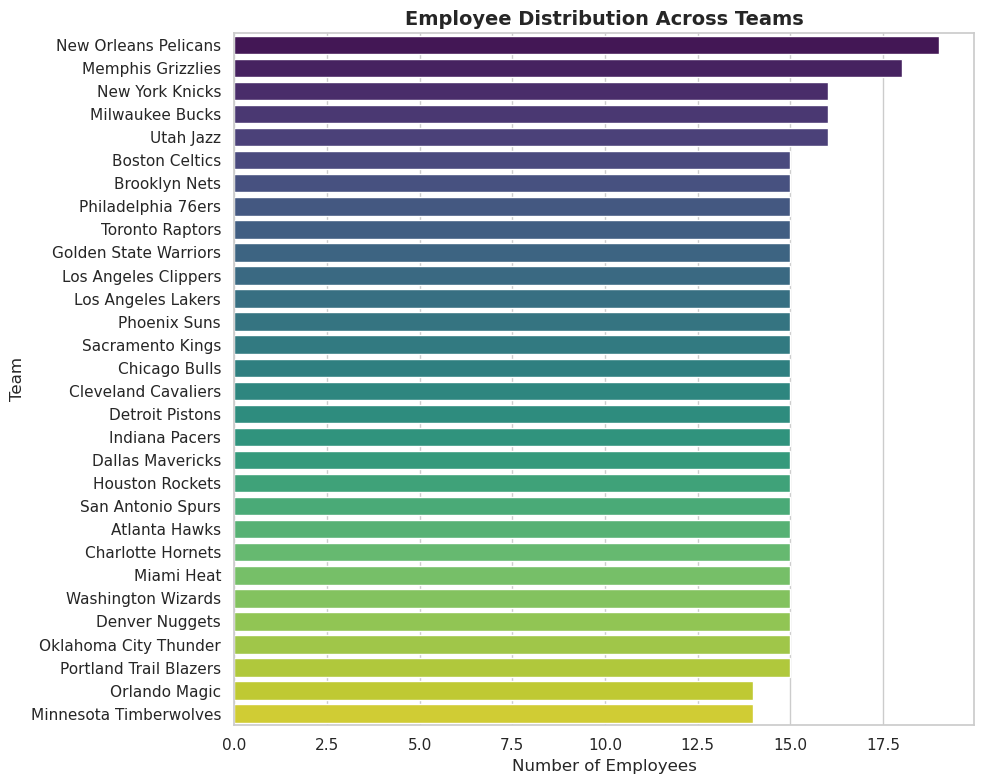

In [3]:
# Count employees per team and compute percentage split
team_counts = df['Team'].value_counts()
team_pct = (team_counts / len(df) * 100).round(2)

team_summary = pd.DataFrame({
    'Employee Count': team_counts,
    'Percentage (%)': team_pct
})
print("--- Employee Distribution by Team ---")
print(team_summary)

# Visualization 1: Horizontal Bar Chart
plt.figure(figsize=(10, 8))
sns.barplot(x=team_counts.values, y=team_counts.index, hue=team_counts.index, palette='viridis', legend=False)
plt.title('Employee Distribution Across Teams', fontsize=14, fontweight='bold')
plt.xlabel('Number of Employees')
plt.ylabel('Team')
plt.tight_layout()
plt.show()


--- Employee Count by Position ---
Position
SG    102
PF    100
PG     92
SF     85
C      79
Name: count, dtype: int64


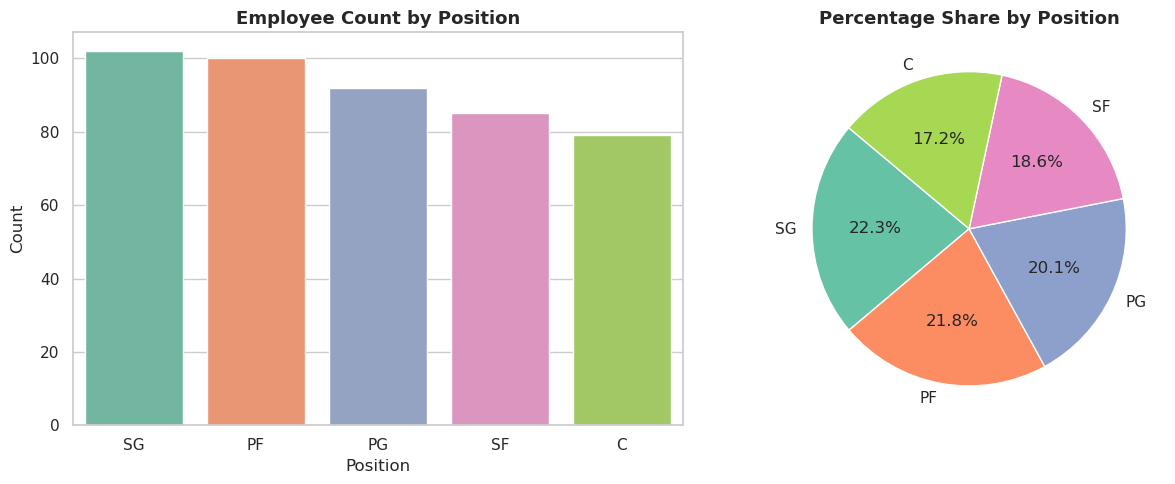

In [4]:
# Count employees per position
pos_counts = df['Position'].value_counts()
print("--- Employee Count by Position ---")
print(pos_counts)

# Visualization 2: Bar Chart & Pie Chart
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(x=pos_counts.index, y=pos_counts.values, hue=pos_counts.index, palette='Set2', legend=False, ax=axes[0])
axes[0].set_title('Employee Count by Position', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Position')
axes[0].set_ylabel('Count')

axes[1].pie(pos_counts.values, labels=pos_counts.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('Set2'))
axes[1].set_title('Percentage Share by Position', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()


--- Employee Count by Age Group ---
Age_Group
19-25    200
26-30    167
31-35     68
36+       23
Name: count, dtype: int64

Predominant Age Group: 19-25 (200 employees)


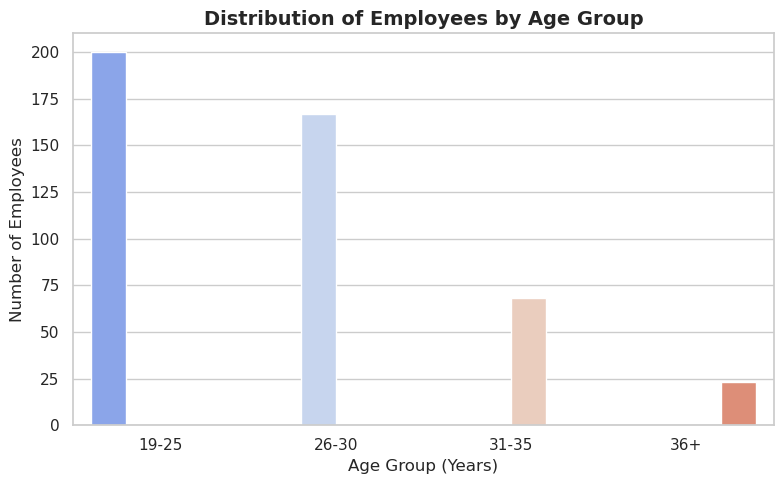

In [5]:
# Group ages into clear brackets
bins = [18, 25, 30, 35, 100]
labels = ['19-25', '26-30', '31-35', '36+']
df['Age_Group'] = pd.cut(df['Age'], bins=bins, labels=labels)

age_counts = df['Age_Group'].value_counts().sort_index()
print("--- Employee Count by Age Group ---")
print(age_counts)
print(f"\nPredominant Age Group: {age_counts.idxmax()} ({age_counts.max()} employees)")

# Visualization 3: Bar Chart
plt.figure(figsize=(8, 5))
sns.barplot(x=age_counts.index, y=age_counts.values, hue=age_counts.index, palette='coolwarm', legend=False)
plt.title('Distribution of Employees by Age Group', fontsize=14, fontweight='bold')
plt.xlabel('Age Group (Years)')
plt.ylabel('Number of Employees')
plt.tight_layout()
plt.show()


Highest Spending Team: Cleveland Cavaliers ($109,824,875)
Highest Spending Position: C ($466,377,332)


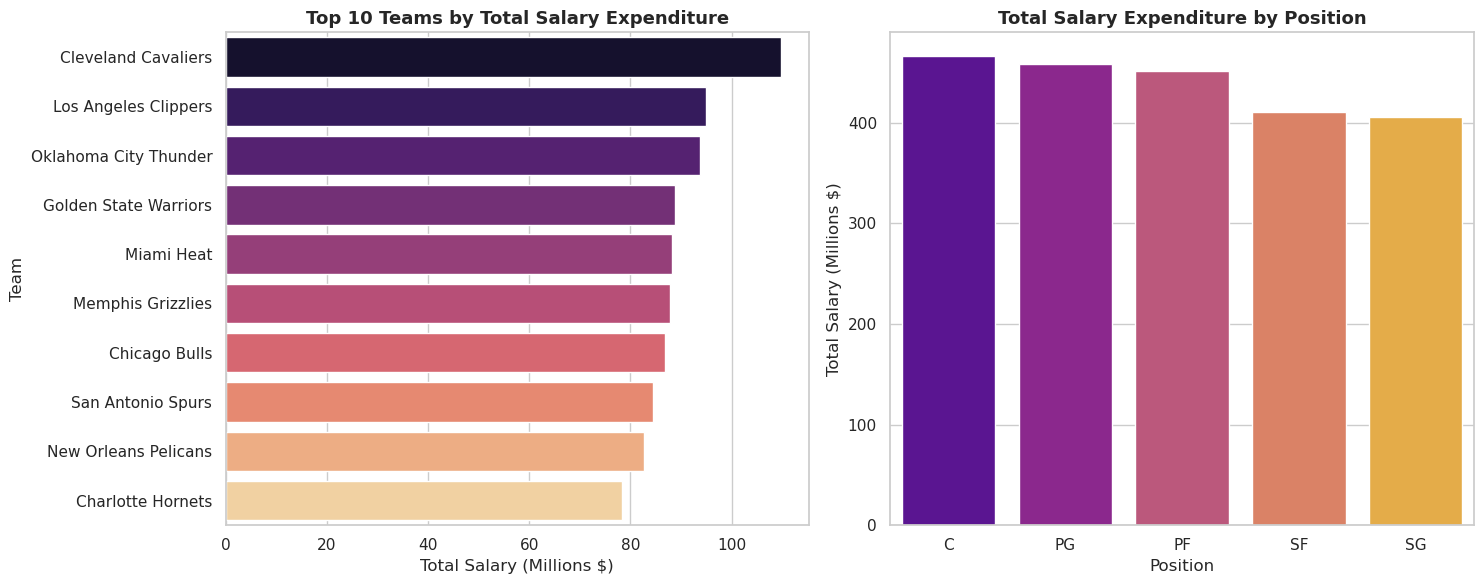

In [6]:
# Group total salary by Team and Position
team_salary = df.groupby('Team')['Salary'].sum().sort_values(ascending=False)
pos_salary = df.groupby('Position')['Salary'].sum().sort_values(ascending=False)

print(f"Highest Spending Team: {team_salary.idxmax()} (${team_salary.max():,.0f})")
print(f"Highest Spending Position: {pos_salary.idxmax()} (${pos_salary.max():,.0f})")

# Visualization 4: Dual Bar Charts
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

top10_teams = team_salary.head(10)
sns.barplot(x=top10_teams.values / 1e6, y=top10_teams.index, hue=top10_teams.index, palette='magma', legend=False, ax=axes[0])
axes[0].set_title('Top 10 Teams by Total Salary Expenditure', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Total Salary (Millions $)')
axes[0].set_ylabel('Team')

sns.barplot(x=pos_salary.index, y=pos_salary.values / 1e6, hue=pos_salary.index, palette='plasma', legend=False, ax=axes[1])
axes[1].set_title('Total Salary Expenditure by Position', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Position')
axes[1].set_ylabel('Total Salary (Millions $)')

plt.tight_layout()
plt.show()


Correlation between Age and Salary: 0.2091


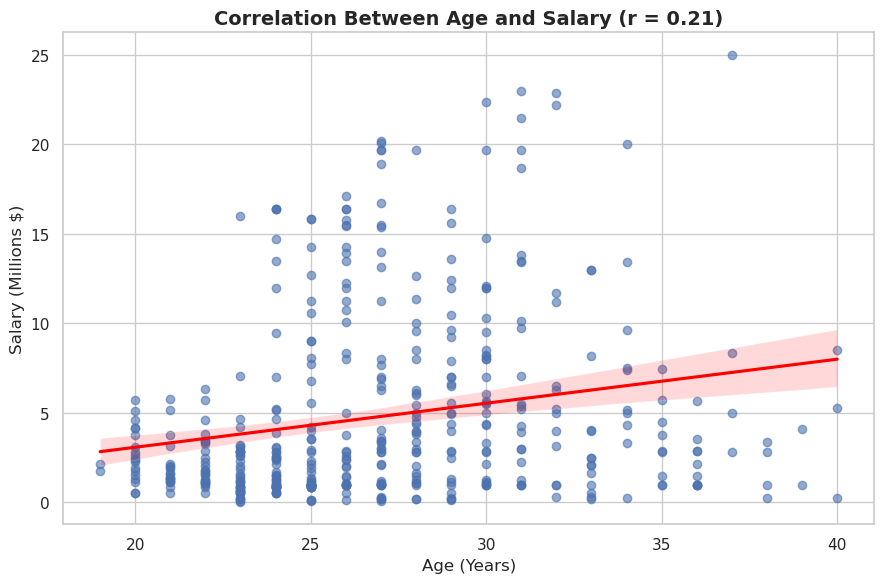

In [7]:
# Compute Pearson correlation coefficient
corr = df['Age'].corr(df['Salary'])
print(f"Correlation between Age and Salary: {corr:.4f}")

# Visualization 5: Scatter Plot with Regression Trendline
plt.figure(figsize=(9, 6))
sns.regplot(data=df, x='Age', y=df['Salary'] / 1e6, scatter_kws={'alpha': 0.6}, line_kws={'color': 'red'})
plt.title(f'Correlation Between Age and Salary (r = {corr:.2f})', fontsize=14, fontweight='bold')
plt.xlabel('Age (Years)')
plt.ylabel('Salary (Millions $)')
plt.tight_layout()
plt.show()
